# 02 — Feature Engineering

We build the final inputs in small, named steps. Repeated joins and historical-window
calculations are reusable functions; six nonlinear formulas remain visible below.
There are **two figures**. Missingness, join examples and feature summaries use tables.

A has 26 schedule/time inputs. Model-specific B packages contain 66 (SVM), 72
(Random Forest) or 78 (LR/KNN) inputs. These are the frozen 2025 choices, not new
selection decisions. [Function definitions](../../scripts/simple_workflow.py)

In [1]:
from pathlib import Path
import sys
here = Path.cwd()
candidates = [here, *here.parents, here/'departure-delay-classification']
root = next(p for p in candidates if (p/'config/project.json').is_file())
sys.path.insert(0, str(root/'scripts'))
import simple_workflow as project

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

Matplotlib is building the font cache; this may take a moment.


## Reuse the same fitting and evaluation identities

Extend the original clean context through July with the rules demonstrated in 01.
Keep all schedules for traffic, including cancellations. Select the frozen 40,000
all-2025 fitting IDs and reproduce the original 10,000-flight July sample.
Sampling is seed-42 proportional month × outcome, preserving natural prevalence.

In [3]:
context = project.load_context()
features = project.shared_queries(context)
display(features.groupby('role')['flight_date'].agg(['size', 'min', 'max']))

2026_04: 85,499 scoped schedules


2026_05: 88,687 scoped schedules


2026_06: 86,150 scoped schedules


2026_07: 89,701 scoped schedules


,size,min,max
role,,,
july_reproduction,10000,2026-07-01,2026-07-31
refit,40000,2025-01-01,2025-12-31


## Schedule and time features

Daily coordinates are sin(2π × minutes/1440) and cos(2π × minutes/1440), keeping
midnight continuous. Month is cyclic too. Second harmonics permit multiple daily
peaks, and airport interactions allow different time patterns. The example table
shows minutes and their resulting coordinates; weekday is categorical.

In [4]:
features = project.calendar_features(features)
example = ['scheduled_departure_minutes', 'departure_sin', 'departure_cos', 'month_sin']
display(features[example].head())

,scheduled_departure_minutes,departure_sin,departure_cos,month_sin
0,638,0.350207,-0.936672,0.0
1,405,0.980785,-0.195090,0.0
2,906,-0.725374,-0.688355,0.0
3,906,-0.725374,-0.688355,0.0
4,430,0.953717,-0.300706,0.0


## Match weather to the two-hour cutoff

Decode archived reports, remove identical payloads and exclude both versions at
approved conflicting times. Unexpected conflicts stop. Select the latest observation
≤cutoff−20 minutes, with age ≤180 minutes at cutoff. For a 12:00 cutoff, 11:40 is
eligible while 11:45 is too recent. Keep unmatched flights with missing weather.

Unknown gust/conditions/ceiling remain unknown. Trace precipitation becomes zero plus
a trace flag. The decoder also calculates dewpoint spread, wind vectors, freezing/wet
status and inclusive prior-three-hour report summaries. Pressure parsing uses the
METAR body before RMK. See the [formula guide](README.md#feature-formulas).

In [5]:
weather, weather_audit = project.read_weather()
features = project.match_weather(features, weather)
example = ['prediction_cutoff_utc', 'weather_observed_utc', 'weather_age_minutes']
display(features[example].head())

,prediction_cutoff_utc,weather_observed_utc,weather_age_minutes
0,2025-01-12 13:38:00+00:00,2025-01-12 12:52:00+00:00,46.0
1,2025-01-12 09:45:00+00:00,2025-01-12 08:52:00+00:00,53.0
2,2025-01-13 19:06:00+00:00,2025-01-13 17:53:00+00:00,73.0
3,2025-01-20 19:06:00+00:00,2025-01-20 17:53:00+00:00,73.0
4,2025-01-02 11:10:00+00:00,2025-01-02 09:53:00+00:00,77.0


In [6]:
fitting = features.loc[features['role'].eq('refit')]
weather_columns = ['temperature_f', 'wind_knots', 'gust_knots', 'ceiling_ft', 'rain_reported']
display(fitting[weather_columns].isna().mean().rename('missing_fraction'))
display(fitting[weather_columns[:3]].describe().T)

temperature_f    0.000000
wind_knots       0.000225
gust_knots       0.808275
ceiling_ft       0.485300
rain_reported    0.904975
Name: missing_fraction, dtype: float64

,count,mean,std,min,25%,50%,75%,max
temperature_f,40000.0,63.477982,19.358720,-8.0,50.0,67.0,78.0,102.0
wind_knots,39991.0,8.263459,4.467079,0.0,5.0,8.0,11.0,32.0
gust_knots,7669.0,22.536837,5.245174,13.0,19.0,22.0,25.0,60.0


Missing fields do not imply an unmatched report. The wind boxplot shows class overlap
on fitting rows; missingness remains explicit until training-only preprocessing.

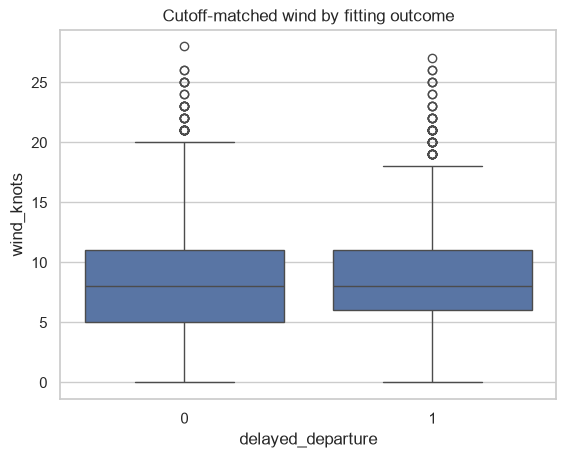

In [7]:
sns.boxplot(data=fitting.sample(5000, random_state=42), x='delayed_departure', y='wind_knots')
plt.title('Cutoff-matched wind by fitting outcome')
plt.show()

## Earlier history and scheduled traffic

Count eligible outcome events in **[cutoff−35 days, cutoff−7 days)** for origin,
airline/origin, route and flight number. Origin risk is delayed/n; subgroup risk is
**(delayed + 20 × origin risk)/(n + 20)**. For 2 delays in 5 flights and origin risk
.30, this gives .32. Counts and no-history flags retain evidence strength.

Traffic counts all origin schedules in **[departure−60 minutes, departure)**.
This is scheduled demand assumed known at cutoff, not actual departures. Timely
outcomes and archived schedule availability remain historical-simulation assumptions.

In [8]:
events = context.loc[context['label_eligible']]
features = project.history_features(features, events)
features = project.traffic_features(features, context)
display(features[['history_origin_rate', 'history_flight_n', 'airport_scheduled_departures_prior_60m']].head())

,history_origin_rate,history_flight_n,airport_scheduled_departures_prior_60m
0,0.235487,27,65
1,0.234999,28,10
2,0.287885,10,62
3,0.321887,8,62
4,0.238888,23,38


The next figure bins earlier airline/origin risk, then measures actual delay rate on
fitting rows. The association supports examining history as an input; it does not
establish causality or guarantee separation between classes.

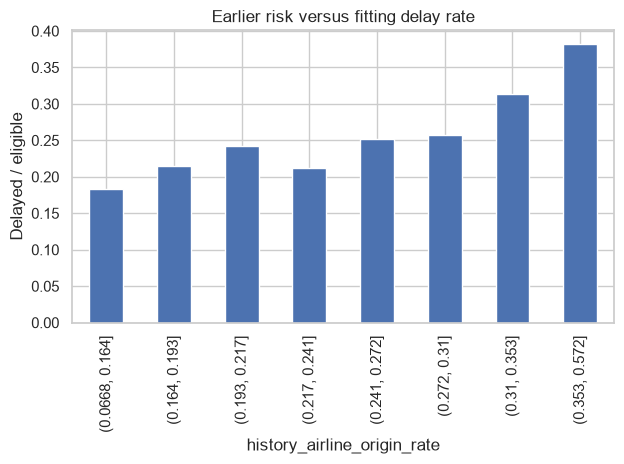

In [9]:
fitting = features.loc[features['role'].eq('refit')]
bins = pd.qcut(fitting['history_airline_origin_rate'], 8, duplicates='drop')
fitting.groupby(bins, observed=True)['delayed_departure'].mean().plot.bar(title='Earlier risk versus fitting delay rate')
plt.ylabel('Delayed / eligible')
plt.tight_layout()
plt.show()

## Pressure and nonlinear representations

A2992 means altimeter setting 29.92 inHg. Join pressure, its inclusive three-hour
change/range, variable-wind flag and gust excess to the already matched report.
Missing/ambiguous pressure stays missing. Change subtracts the first valid pressure.
The six formulas below preserve unknown measurements while exposing curvature and
diminishing scale to the basic classifiers. No new feature selection occurs.

In [10]:
features = project.pressure_features(features, weather)
display(features[['altimeter_inhg', 'altimeter_change3h_inhg', 'variable_wind_flag']].head())

,altimeter_inhg,altimeter_change3h_inhg,variable_wind_flag
0,30.08,0.04,0.0
1,30.03,-0.01,0.0
2,30.41,0.00,0.0
3,30.55,-0.01,0.0
4,30.26,-0.02,0.0


In [11]:
features['temperature_centered_square'] = ((features['temperature_f']-32)/10)**2
features['wind_square'] = features['wind_knots']**2
features['dewpoint_spread_square'] = features['dewpoint_spread_f']**2
features['precip_log1p'] = np.log1p(features['precip_inches'])
features['ceiling_log1p'] = np.log1p(features['ceiling_ft'])
features['visibility_inverse'] = 1/(1+features['visibility_miles'])

## Save one unscaled feature handoff

The table contains labels and audit fields too, so 03 selects X through explicit
frozen allowlists. Save only the existing reproduction Parquet path; the two original
processed tables stay unchanged. Independent verification compares all 78 selected
features and missing values on all 50,000 rows with the previous calculations.

In [12]:
project.save_features(features, weather_audit)

Saved unscaled features: {'july_reproduction': 10000, 'refit': 40000}


Continue to [03 — Model Training](03_model_training.ipynb).